In [77]:
import numpy as np 
import pandas as pd 
import seaborn as sns 
import matplotlib.pyplot as plt 
import warnings 

from sklearn.preprocessing import StandardScaler

from scipy.stats import pearsonr
from scipy.stats import chi2_contingency

warnings.filterwarnings('ignore')


In [78]:
#steps for eda 
df = pd.read_csv('insurance.csv')
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [ ]:
df.shape
# selected the datashape like row and columns 

(1338, 7)

In [81]:
df.head()
# printing the head of dataset (top 5 values)

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [83]:
df.info()
# printing the information about the dataswt 

<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB


# Output Explanation (`df.describe()`) – Insurance Dataset

`df.describe()` generates a **statistical summary** of all numerical columns in the dataset. It helps understand the distribution, spread, and central tendency of the data before training a machine learning model.

## Output Explanation Table

| **Statistic** | **Meaning** | **Example from Insurance Dataset** |
|---------------|-------------|------------------------------------|
| `count` | Number of non-null (non-missing) values in each column. | `1338` → All numerical columns contain **1338 values**, indicating no missing values. |
| `mean` | Average value of the column. | Average age = **39.21**, Average BMI = **30.66**, Average insurance charges = **13270.42**. |
| `std` | Standard deviation, showing how much the values vary from the mean. | Charges have a standard deviation of **12110**, indicating a large variation in medical expenses. |
| `min` | Minimum (smallest) value in the column. | Minimum insurance charges = **1121.87**. |
| `25%` | First quartile (Q1). 25% of observations lie below this value. | 25% of people have insurance charges below **4740.29**. |
| `50%` | Median (Q2), the middle value of the dataset. | Median insurance charges = **9382.03**. |
| `75%` | Third quartile (Q3). 75% of observations lie below this value. | 75% of people have insurance charges below **16639.91**. |
| `max` | Maximum (largest) value in the column. | Maximum insurance charges = **63770.43**. |

---

## Interpretation of the Insurance Dataset

- **Age:** The dataset contains individuals aged **18 to 64 years**, with an average age of **39.21 years**.
- **BMI:** The average BMI is **30.66**, indicating that many individuals fall into the overweight or obese category.
- **Children:** The number of children ranges from **0 to 5**, with an average of **1.09 children** per person.
- **Charges:** Insurance charges range from **1121.87** to **63770.43**. The mean (**13270.42**) is higher than the median (**9382.03**), suggesting that the `charges` variable is **positively (right) skewed** due to some very high medical expenses.

---

## Why `df.describe()` is Used in Machine Learning

`df.describe()` is an important **Exploratory Data Analysis (EDA)** step because it helps to:

- Check for missing values using the `count` statistic.
- Understand the average and spread of each numerical feature.
- Identify the range (`min` and `max`) of feature values.
- Detect potential outliers by comparing quartiles with the maximum value.
- Decide whether feature scaling or normalization is required before model training.

> **Conclusion:** `df.describe()` provides a quick statistical overview of the dataset and helps understand the characteristics of numerical features before building a machine learning model to predict insurance charges.

In [85]:
df.describe()

,age,bmi,children,charges
count,1338.000000,1338.000000,1338.000000,1338.000000
mean,39.207025,30.663397,1.094918,13270.422265
std,14.049960,6.098187,1.205493,12110.011237
min,18.000000,15.960000,0.000000,1121.873900
25%,27.000000,26.296250,0.000000,4740.287150
50%,39.000000,30.400000,1.000000,9382.033000
75%,51.000000,34.693750,2.000000,16639.912515
max,64.000000,53.130000,5.000000,63770.428010


In [138]:
df.isnull().sum()
# check for null value present in dataset 

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [87]:
print(df.columns)
print("\n")
print(df.info())

Index(['age', 'sex', 'bmi', 'children', 'smoker', 'region', 'charges'], dtype='str')


<class 'pandas.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   str    
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   str    
 5   region    1338 non-null   str    
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), str(3)
memory usage: 73.3 KB
None


# Histogram Plotting of Numerical Features

## Why is this used?

This code is used during the **Exploratory Data Analysis (EDA)** phase of the Insurance Charges Prediction project. It plots a histogram for each numerical feature to understand the distribution of the data before training the machine learning model.

### Purpose of Plotting Histograms

- Visualize the distribution of numerical features.
- Identify whether the data is **normally distributed** or **skewed**.
- Detect **outliers** and extreme values.
- Understand the spread and frequency of values.
- Analyze the target variable (`charges`) before building a regression model.

---

## Why each feature is plotted?

| **Feature** | **Purpose in Insurance Dataset** |
|--------------|----------------------------------|
| `age` | Shows the distribution of people's ages (18–64 years). |
| `bmi` | Helps identify the distribution of BMI values and possible high BMI outliers. |
| `children` | Shows the frequency of people having 0, 1, 2, ..., 5 children. |
| `charges` | Visualizes the distribution of insurance charges and checks whether the target variable is skewed. |

---

## Interpretation for the Insurance Dataset

- **Age:** Ages are distributed between **18 and 64 years**.
- **BMI:** Most BMI values are concentrated around **25–35**.
- **Children:** The majority of individuals have **0 or 1 child**.
- **Charges:** The distribution is **positively (right) skewed**, meaning most people have lower medical charges while a few have very high charges.

---

## Conclusion

Histograms help understand the distribution and spread of numerical features in the insurance dataset. This analysis is useful for identifying skewness, outliers, and data patterns before training a machine learning model to predict insurance charges.

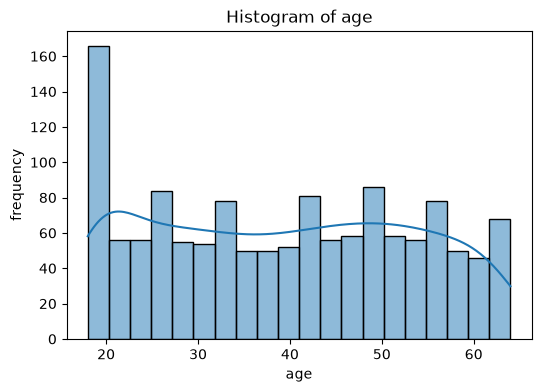

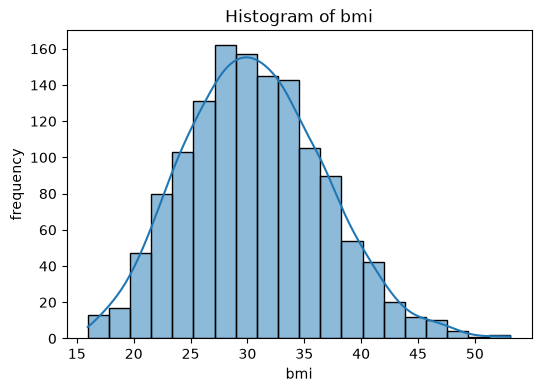

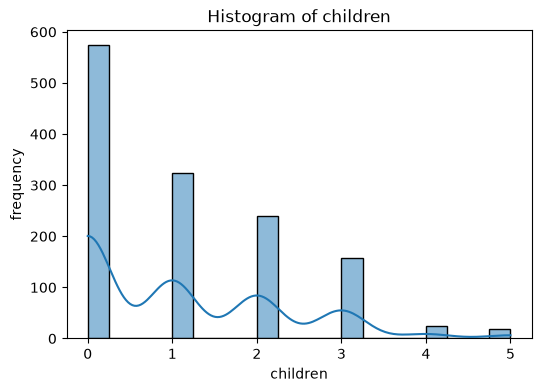

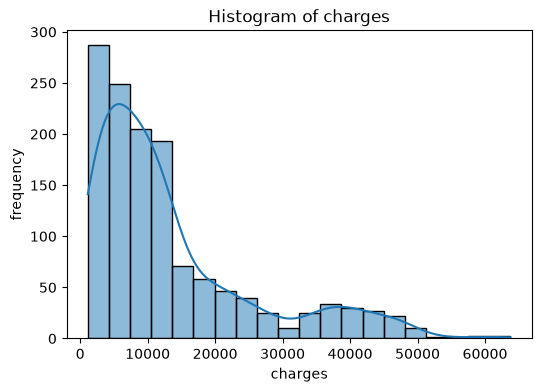

In [88]:
#ploting histogram of each data
numeric_columns = ['age' , 'bmi' , 'children' , 'charges']
for col in numeric_columns:
    plt.figure(figsize=(6 , 4))
    sns.histplot(df[col] , kde=True , bins= 20)
    plt.title(f'Histogram of {col}')
    plt.xlabel(col)
    plt.ylabel('frequency')
    plt.show()

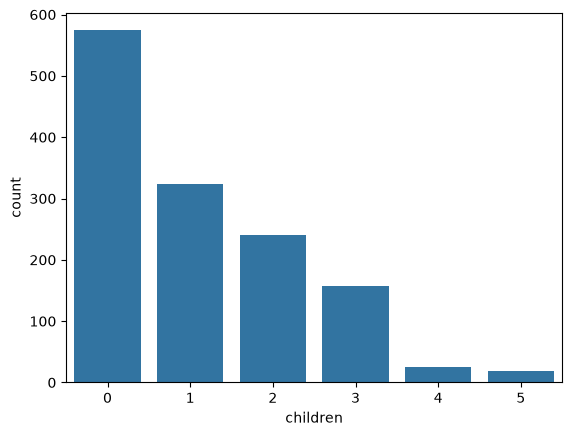

In [89]:
# for new version
sns.countplot(x=df['children'])
plt.show()


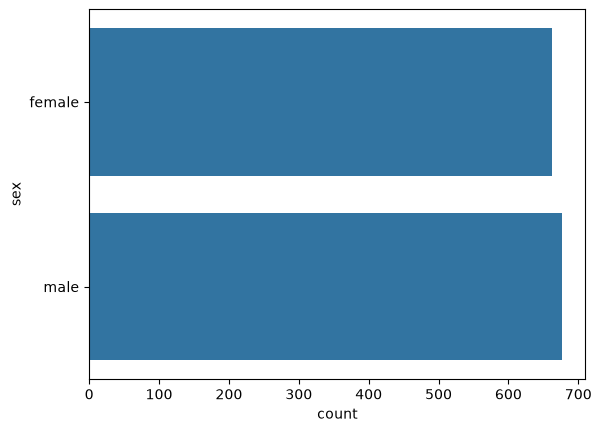

In [90]:
sns.countplot(y=df['sex'])
plt.show()

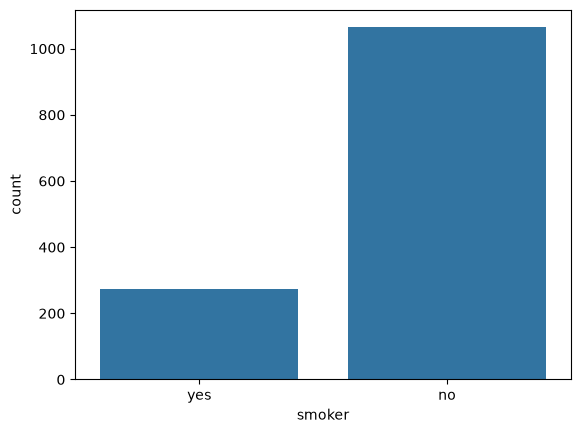

In [91]:
sns.countplot(x=df['smoker'])
plt.show()

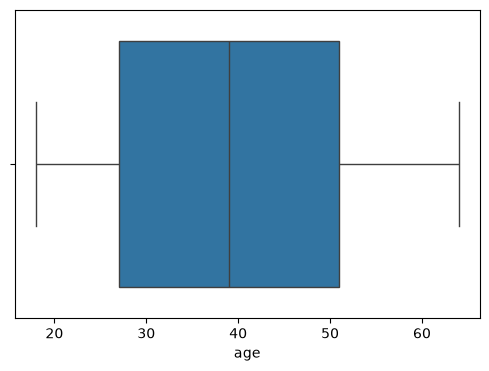

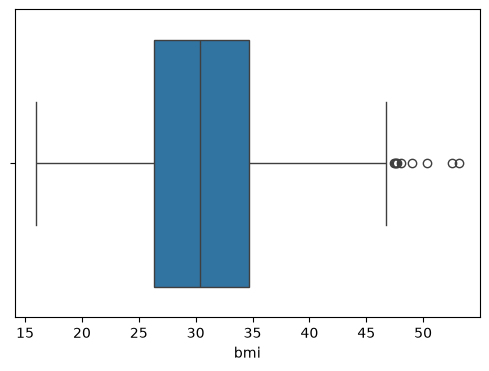

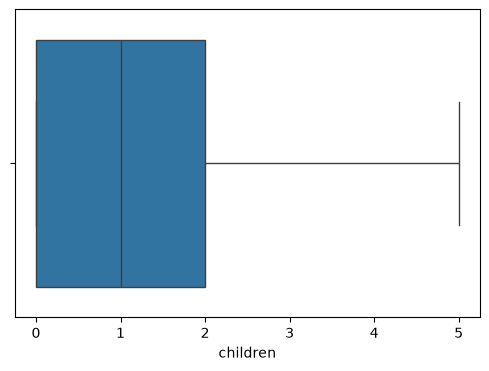

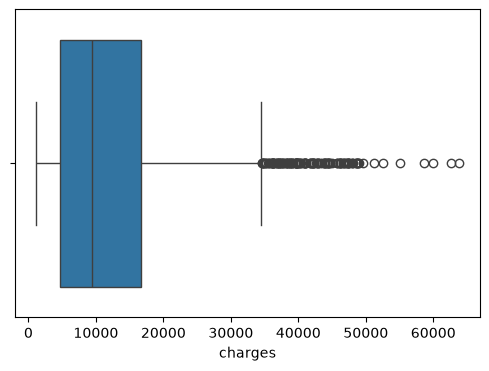

In [92]:
for col in numeric_columns:
    plt.figure(figsize=(6 , 4))
    sns.boxplot(x = df[col])
    

<Axes: >

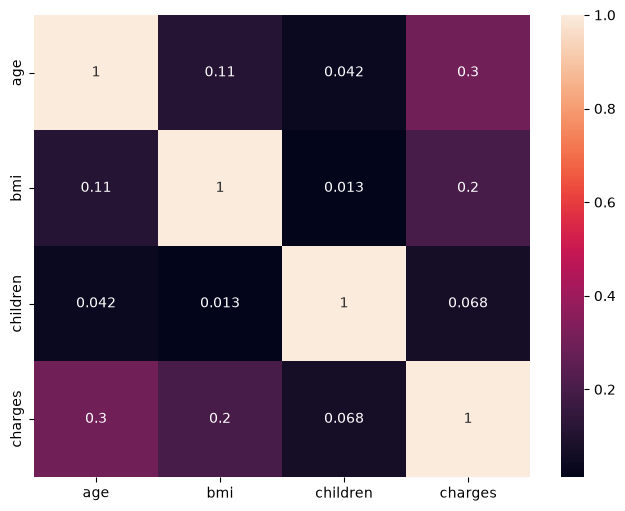

In [93]:
plt.figure(figsize=(8 , 6))
sns.heatmap(df.corr(numeric_only= True) , annot = True)

In [94]:
# data cleaning and processing 

In [146]:
df

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520
...,...,...,...,...,...,...,...
1333,50,male,30.970,3,no,northwest,10600.54830
1334,18,female,31.920,0,no,northeast,2205.98080
1335,18,female,36.850,0,no,southeast,1629.83350
1336,21,female,25.800,0,no,southwest,2007.94500


In [ ]:
df_cleaned = df.copy()
df_cleaned.shape

(1338, 7)

In [96]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


In [97]:
df_cleaned.shape

(1338, 7)

In [98]:
df_cleaned.isnull().sum()

age         0
sex         0
bmi         0
children    0
smoker      0
region      0
charges     0
dtype: int64

In [99]:
df_cleaned.dtypes

age           int64
sex             str
bmi         float64
children      int64
smoker          str
region          str
charges     float64
dtype: object

In [100]:
df_cleaned['sex'].value_counts()

sex
male      676
female    662
Name: count, dtype: int64

In [101]:
df_cleaned['sex'] = df_cleaned['sex'].map({"male" : 0 , "female" : 1})

In [102]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,yes,southwest,16884.92400
1,18,0,33.770,1,no,southeast,1725.55230
2,28,0,33.000,3,no,southeast,4449.46200
3,33,0,22.705,0,no,northwest,21984.47061
4,32,0,28.880,0,no,northwest,3866.85520


In [103]:
df_cleaned['smoker'].value_counts()

smoker
no     1064
yes     274
Name: count, dtype: int64

In [104]:
print(df_cleaned['smoker'].unique())

<StringArray>
['yes', 'no']
Length: 2, dtype: str


In [105]:
df_cleaned['smoker'] = df_cleaned['smoker'].replace({'yes': 1, 'no': 0})

In [106]:
df_cleaned.head()

,age,sex,bmi,children,smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [107]:
df_cleaned['smoker'].head()

0    1
1    0
2    0
3    0
4    0
Name: smoker, dtype: object

In [108]:
df_cleaned.rename(columns={
    'sex' : 'is_female' , 
    'smoker' : 'is_smoker'
} , inplace = True )

In [109]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,region,charges
0,19,1,27.900,0,1,southwest,16884.92400
1,18,0,33.770,1,0,southeast,1725.55230
2,28,0,33.000,3,0,southeast,4449.46200
3,33,0,22.705,0,0,northwest,21984.47061
4,32,0,28.880,0,0,northwest,3866.85520


In [110]:
df['region'].value_counts()

region
southeast    364
southwest    325
northwest    325
northeast    324
Name: count, dtype: int64

In [ ]:
df_cleaned = pd.get_dummies(df_cleaned , columns=['region'] , dtype=int)

In [142]:
df_cleaned.sample(5)

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obese,charges_bin
1133,0.910875,1,-2.022405,-0.908614,0,9991.03765,0,1,0,0,1,0,0,0,2
570,-0.584350,1,-0.256467,-0.908614,0,3761.29200,0,0,0,1,0,0,1,0,0
724,0.768473,1,-0.588657,-0.078767,0,10106.13425,1,0,0,0,0,0,1,0,2
950,1.266881,0,-2.022405,-0.908614,0,11534.87265,1,0,0,0,1,0,0,0,2
810,0.483668,1,0.022409,1.580926,0,9414.92000,0,0,0,1,0,0,0,1,2


In [143]:
df_cleaned.describe()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obese,charges_bin
count,1.338000e+03,1338.000000,1.338000e+03,1.338000e+03,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,-1.805565e-16,0.494768,-2.124194e-16,-5.576008e-17,0.204783,13270.422265,0.242152,0.242900,0.272048,0.242900,0.015695,0.165172,0.284006,0.535127,1.500000
std,1.000374e+00,0.500160,1.000374e+00,1.000374e+00,0.403694,12110.011237,0.428546,0.428995,0.445181,0.428995,0.124339,0.371474,0.451108,0.498951,1.119121
min,-1.509965e+00,0.000000,-2.412011e+00,-9.086137e-01,0.000000,1121.873900,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-8.691547e-01,0.000000,-7.164063e-01,-9.086137e-01,0.000000,4740.287150,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.250000
50%,-1.474046e-02,0.000000,-4.320880e-02,-7.876719e-02,0.000000,9382.033000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.500000
75%,8.396738e-01,1.000000,6.611572e-01,7.510793e-01,0.000000,16639.912515,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2.750000
max,1.765289e+00,1.000000,3.685522e+00,3.240619e+00,1.000000,63770.428010,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


In [113]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest
0,19,1,27.900,0,1,16884.92400,0,0,0,1
1,18,0,33.770,1,0,1725.55230,0,0,1,0
2,28,0,33.000,3,0,4449.46200,0,0,1,0
3,33,0,22.705,0,0,21984.47061,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0
...,...,...,...,...,...,...,...,...,...,...
1333,50,0,30.970,3,0,10600.54830,0,1,0,0
1334,18,1,31.920,0,0,2205.98080,1,0,0,0
1335,18,1,36.850,0,0,1629.83350,0,0,1,0
1336,21,1,25.800,0,0,2007.94500,0,0,0,1


In [114]:
# feature enginerring and ectraction 


<Axes: xlabel='bmi', ylabel='Count'>

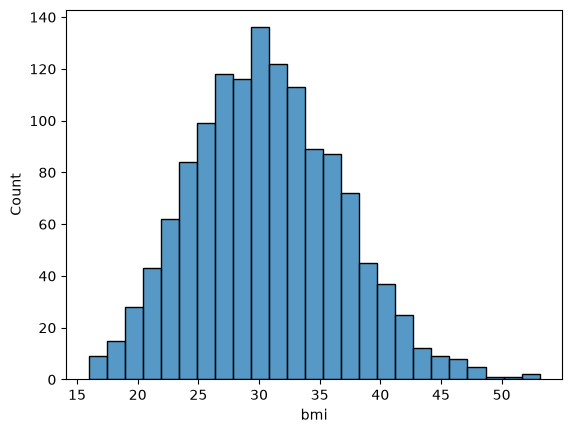

In [115]:
sns.histplot(df['bmi'])

In [116]:
df_cleaned['bmi_category'] = pd.cut(
    df_cleaned['bmi'] , 
    bins=[0 , 18.5 , 24.9 , 29.9 , float('inf')] , 
    labels=['underweight' , 'normal' , 'overweight' , 'obese']
)

In [140]:
df_cleaned.describe()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obese,charges_bin
count,1.338000e+03,1338.000000,1.338000e+03,1.338000e+03,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000,1338.000000
mean,-1.805565e-16,0.494768,-2.124194e-16,-5.576008e-17,0.204783,13270.422265,0.242152,0.242900,0.272048,0.242900,0.015695,0.165172,0.284006,0.535127,1.500000
std,1.000374e+00,0.500160,1.000374e+00,1.000374e+00,0.403694,12110.011237,0.428546,0.428995,0.445181,0.428995,0.124339,0.371474,0.451108,0.498951,1.119121
min,-1.509965e+00,0.000000,-2.412011e+00,-9.086137e-01,0.000000,1121.873900,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,-8.691547e-01,0.000000,-7.164063e-01,-9.086137e-01,0.000000,4740.287150,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.250000
50%,-1.474046e-02,0.000000,-4.320880e-02,-7.876719e-02,0.000000,9382.033000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.500000
75%,8.396738e-01,1.000000,6.611572e-01,7.510793e-01,0.000000,16639.912515,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,1.000000,1.000000,2.750000
max,1.765289e+00,1.000000,3.685522e+00,3.240619e+00,1.000000,63770.428010,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,1.000000,3.000000


In [118]:
df_cleaned['bmi_category'].value_counts()

bmi_category
obese          716
overweight     380
normal         221
underweight     21
Name: count, dtype: int64

In [119]:
df_cleaned = pd.get_dummies(df_cleaned , columns=['bmi_category'] , dtype=int)

In [120]:
df_cleaned.head()

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,19,1,27.900,0,1,16884.92400,0,0,0,1,0,0,1,0
1,18,0,33.770,1,0,1725.55230,0,0,1,0,0,0,0,1
2,28,0,33.000,3,0,4449.46200,0,0,1,0,0,0,0,1
3,33,0,22.705,0,0,21984.47061,0,1,0,0,0,1,0,0
4,32,0,28.880,0,0,3866.85520,0,1,0,0,0,0,1,0


In [121]:
df_cleaned.columns

Index(['age', 'is_female', 'bmi', 'children', 'is_smoker', 'charges',
       'region_northeast', 'region_northwest', 'region_southeast',
       'region_southwest', 'bmi_category_underweight', 'bmi_category_normal',
       'bmi_category_overweight', 'bmi_category_obese'],
      dtype='str')

In [ ]:
cols = ['age' , 'bmi' , 'children']
scaler = StandardScaler()
# used for shrinking the data 
df_cleaned[cols] = scaler.fit_transform(df_cleaned[cols])

In [123]:
df_cleaned

,age,is_female,bmi,children,is_smoker,charges,region_northeast,region_northwest,region_southeast,region_southwest,bmi_category_underweight,bmi_category_normal,bmi_category_overweight,bmi_category_obese
0,-1.438764,1,-0.453320,-0.908614,1,16884.92400,0,0,0,1,0,0,1,0
1,-1.509965,0,0.509621,-0.078767,0,1725.55230,0,0,1,0,0,0,0,1
2,-0.797954,0,0.383307,1.580926,0,4449.46200,0,0,1,0,0,0,0,1
3,-0.441948,0,-1.305531,-0.908614,0,21984.47061,0,1,0,0,0,1,0,0
4,-0.513149,0,-0.292556,-0.908614,0,3866.85520,0,1,0,0,0,0,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1333,0.768473,0,0.050297,1.580926,0,10600.54830,0,1,0,0,0,0,0,1
1334,-1.509965,1,0.206139,-0.908614,0,2205.98080,1,0,0,0,0,0,0,1
1335,-1.509965,1,1.014878,-0.908614,0,1629.83350,0,0,1,0,0,0,0,1
1336,-1.296362,1,-0.797813,-0.908614,0,2007.94500,0,0,0,1,0,0,1,0


In [124]:
# For your dataset (modify according to your column names):
selected_features = [
    'age',
    'bmi',
    'children',
    'is_smoker',
    'is_female',
    'region_northeast',
    'region_northwest',
    'region_southeast',
    'region_southwest' , 
    'bmi_category_underweight' , 
    'bmi_category_normal' , 
    'bmi_category_overweight' , 
    'bmi_category_obese'
]

In [125]:
# print(df_cleaned.dtypes)
# print(df_cleaned['is_smoker'].unique())
# print(df_cleaned['is_smoker'].dtype)
# print(type(df_cleaned['is_smoker'].iloc[0]))
# print(type(df_cleaned['is_smoker'].iloc[1]))

df_cleaned['is_smoker'] = df_cleaned['is_smoker'].astype('int64')

In [126]:
# Calculate Pearson correlation with the target (charges)
results_ori = []
for feature in selected_features:
    corr, p_value = pearsonr(df_cleaned[feature], df_cleaned['charges'])
    # print(f"{feature:20} Correlation = {corr:.4f}, P-value = {p_value:.6f}")
    results_ori.append([feature , corr , p_value])

In [127]:
# directly printing the output 
print(f'feature   correlation   p_value')
for feature, corr, p_value in results_ori:
    print(f'{feature:25} {corr:.4f} {p_value:.6e}')

feature   correlation   p_value
age                       0.2990 4.886693e-29
bmi                       0.1983 2.459086e-13
children                  0.0680 1.285213e-02
is_smoker                 0.7873 8.271436e-283
is_female                 -0.0573 3.613272e-02
region_northeast          0.0063 8.165264e-01
region_northwest          -0.0399 1.445970e-01
region_southeast          0.0740 6.782699e-03
region_southwest          -0.0432 1.141466e-01
bmi_category_underweight  -0.0481 7.850385e-02
bmi_category_normal       -0.1053 1.140688e-04
bmi_category_overweight   -0.1178 1.568623e-05
bmi_category_obese        0.1969 3.723538e-13


In [128]:
# making tablewith array 
results_ori_table = pd.DataFrame(results_ori , columns=["Features" , "Correlation" , "P_Value"])

# printing the table 
results_ori_table

,Features,Correlation,P_Value
0,age,0.299008,4.886693e-29
1,bmi,0.198341,2.459086e-13
2,children,0.067998,1.285213e-02
3,is_smoker,0.787251,8.271436e-283
4,is_female,-0.057292,3.613272e-02
5,region_northeast,0.006349,8.165264e-01
6,region_northwest,-0.039905,1.445970e-01
7,region_southeast,0.073982,6.782699e-03
8,region_southwest,-0.043210,1.141466e-01
9,bmi_category_underweight,-0.048117,7.850385e-02


In [129]:
# sorting the table 
results_ori_table_sorted_ascending = results_ori_table.sort_values(by="Correlation") 
results_ori_table_sorted_ascending


,Features,Correlation,P_Value
11,bmi_category_overweight,-0.117768,1.568623e-05
10,bmi_category_normal,-0.105291,1.140688e-04
4,is_female,-0.057292,3.613272e-02
9,bmi_category_underweight,-0.048117,7.850385e-02
8,region_southwest,-0.043210,1.141466e-01
6,region_northwest,-0.039905,1.445970e-01
5,region_northeast,0.006349,8.165264e-01
2,children,0.067998,1.285213e-02
7,region_southeast,0.073982,6.782699e-03
12,bmi_category_obese,0.196857,3.723538e-13


In [130]:
# sorting the table 
results_ori_table_sorted_not_ascending = results_ori_table.sort_values(by="Correlation" , ascending=False) 
results_ori_table_sorted_not_ascending


,Features,Correlation,P_Value
3,is_smoker,0.787251,8.271436e-283
0,age,0.299008,4.886693e-29
1,bmi,0.198341,2.459086e-13
12,bmi_category_obese,0.196857,3.723538e-13
7,region_southeast,0.073982,6.782699e-03
2,children,0.067998,1.285213e-02
5,region_northeast,0.006349,8.165264e-01
6,region_northwest,-0.039905,1.445970e-01
8,region_southwest,-0.043210,1.141466e-01
9,bmi_category_underweight,-0.048117,7.850385e-02


In [131]:
# print without index 
print(results_ori_table_sorted_not_ascending.to_string(index=False))


                Features  Correlation       P_Value
               is_smoker     0.787251 8.271436e-283
                     age     0.299008  4.886693e-29
                     bmi     0.198341  2.459086e-13
      bmi_category_obese     0.196857  3.723538e-13
        region_southeast     0.073982  6.782699e-03
                children     0.067998  1.285213e-02
        region_northeast     0.006349  8.165264e-01
        region_northwest    -0.039905  1.445970e-01
        region_southwest    -0.043210  1.141466e-01
bmi_category_underweight    -0.048117  7.850385e-02
               is_female    -0.057292  3.613272e-02
     bmi_category_normal    -0.105291  1.140688e-04
 bmi_category_overweight    -0.117768  1.568623e-05


In [132]:
# Categorical features selected after Chi-Square

selected_features = [
    'age',
    'children',
    'is_smoker',
    'is_female',
    'region_southeast'
]


In [148]:
# applying chi2 operations 

alpha = 0.05 

df_cleaned['charges_bin'] = pd.qcut(df_cleaned['charges'] , q = 4 , labels=False) 
chi2_results = {} 

for col in selected_features:
    contingency = pd.crosstab(df_cleaned[col] , df_cleaned['charges_bin'])
    chi2_stats , p_val , _ , _ = chi2_contingency(contingency) 
    decision = 'Reject Null (Keep Feature)' if p_val < alpha else 'Accept Null (Drop Feature)'
    chi2_results[col] = {
        'chi2_statistic' : chi2_stats , 
        'p_value' : p_val , 
        'Decision' : decision
    }
# chi2_results

In [134]:
# output in table 
chi2_results_table = pd.DataFrame(chi2_results)
chi2_results_table

,age,children,is_smoker,is_female,region_southeast
chi2_statistic,1521.204566,139.565803,854.020268,9.532132,15.208814
p_value,0.0,0.0,0.0,0.022992,0.001647
Decision,Reject Null (Keep Feature),Reject Null (Keep Feature),Reject Null (Keep Feature),Reject Null (Keep Feature),Reject Null (Keep Feature)


In [135]:
# drop it 
# drop_features = [
#     'region_northeast',
#     'region_northwest',
#     'region_southwest',
#     'bmi_category_underweight',
#     'bmi_category_normal',
#     'bmi_category_overweight',
#     'bmi_category_obese'
# ]

In [136]:
# selected feature for model train
selected_features_for_model = [
    'age',
    'bmi',
    'children',
    'is_smoker',
    'is_female',
    'region_northwest',
    'region_southeast',
    'region_southwest'
]
selected_features_for_model


['age',
 'bmi',
 'children',
 'is_smoker',
 'is_female',
 'region_northwest',
 'region_southeast',
 'region_southwest']

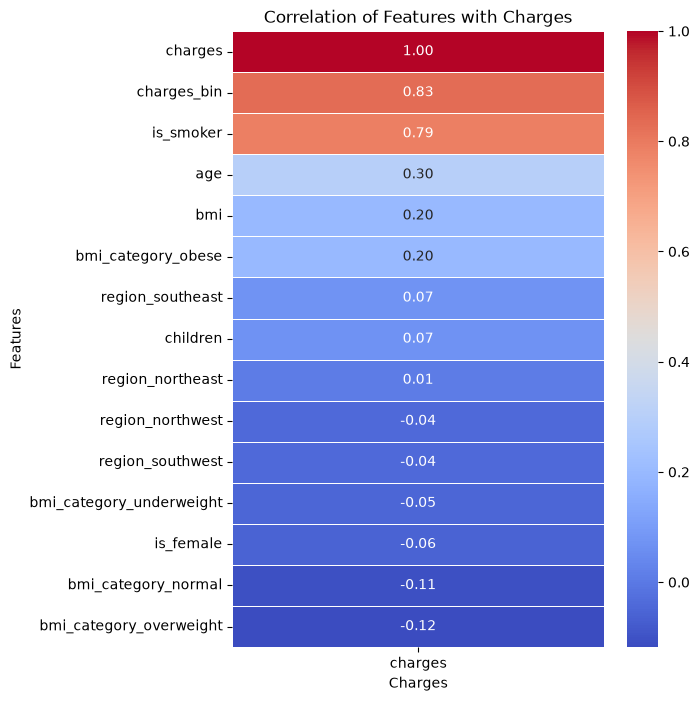

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Correlation of all features with charges
corr_with_charges = df_cleaned.corr(numeric_only=True)[['charges']].sort_values(
    by='charges', ascending=False
)
# select only numeric value and and sort the data according to their impact on charges 

plt.figure(figsize=(6,8))
sns.heatmap(
    corr_with_charges,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation of Features with Charges")
plt.xlabel("Charges")
plt.ylabel("Features")
plt.show()

In [156]:
selected_features = [
    'age',
    'bmi',
    'children',
    'is_smoker',
    'is_female',
    'region_northwest',
    'region_southeast',
    'region_southwest'
]
selected_features

['age',
 'bmi',
 'children',
 'is_smoker',
 'is_female',
 'region_northwest',
 'region_southeast',
 'region_southwest']

In [179]:
# dependencies for tain model 
from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [155]:
# dependencies for training data
X = df_cleaned[selected_features]

# to be predicted by model
Y = df_cleaned['charges']

In [158]:
X_train , X_test , Y_train , Y_test = train_test_split(
    X , 
    Y , 
    test_size = 0.20 , # 80% training data and 20% testing data  
    random_state = 42 # insure reproductive result 
)

In [161]:
# Just verifying the split
print("X_train:", X_train.shape)
print("X_test :", X_test.shape)
print("Y_train:", Y_train.shape)
print("Y_test :", Y_test.shape)

X_train: (1070, 8)
X_test : (268, 8)
Y_train: (1070,)
Y_test : (268,)


In [ ]:
# Regression Models
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from xgboost import XGBRegressor

In [166]:
# creating a model with importing these necessecity 

models = {
    "LinearRegression": LinearRegression() , 
    "DecisionTreeRegressor": DecisionTreeRegressor(random_state=42) ,
    "RandomForestRegressor": RandomForestRegressor(random_state=42) , 
    "Gradient Boosting": GradientBoostingRegressor(random_state=42)
}

In [176]:
# training the model and store them 
trained_model = {} 

for name , model in models.items():
    model.fit(X_train , Y_train)
    trained_model[name] = model
    print(f'Training for model {name} ends...')


Training for model LinearRegression ends...
Training for model DecisionTreeRegressor ends...
Training for model RandomForestRegressor ends...
Training for model Gradient Boosting ends...


In [177]:
#testing on test data 
predictions = {}

for name, mdl in trained_model.items():
    predictions[name] = mdl.predict(X_test)
    print(f"{name} prediction completed.")

LinearRegression prediction completed.
DecisionTreeRegressor prediction completed.
RandomForestRegressor prediction completed.
Gradient Boosting prediction completed.


In [180]:
# store the predicted result
results = []

for name, y_pred in predictions.items():
    results.append({
        "Model": name,
        "MAE": mean_absolute_error(Y_test, y_pred),
        "MSE": mean_squared_error(Y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(Y_test, y_pred)),
        "R2 Score": r2_score(Y_test, y_pred)
    })

results_df = pd.DataFrame(results).sort_values(by="R2 Score", ascending=False)
results_df

,Model,MAE,MSE,RMSE,R2 Score
3,Gradient Boosting,2450.932060,1.882554e+07,4338.841064,0.878739
2,RandomForestRegressor,2520.144629,2.059292e+07,4537.942272,0.867355
0,LinearRegression,4181.194474,3.359692e+07,5796.284659,0.783593
1,DecisionTreeRegressor,3101.491040,4.109564e+07,6410.588406,0.735292


In [182]:
# Predict using the best model
best_model = trained_model["Gradient Boosting"]
y_pred = best_model.predict(X_test)

# Compare actual vs predicted values
comparison = pd.DataFrame({
    "Actual Charges": Y_test.values,
    "Predicted Charges": y_pred
})

comparison.head(10)

,Actual Charges,Predicted Charges
0,9095.06825,10825.369522
1,5272.17580,5794.881352
2,29330.98315,27836.174124
3,9301.89355,10011.452146
4,33750.29180,33446.034083
5,4536.25900,5410.894701
6,2117.33885,3522.884922
7,14210.53595,16800.836409
8,3732.62510,4661.392909
9,10264.44210,10985.281470


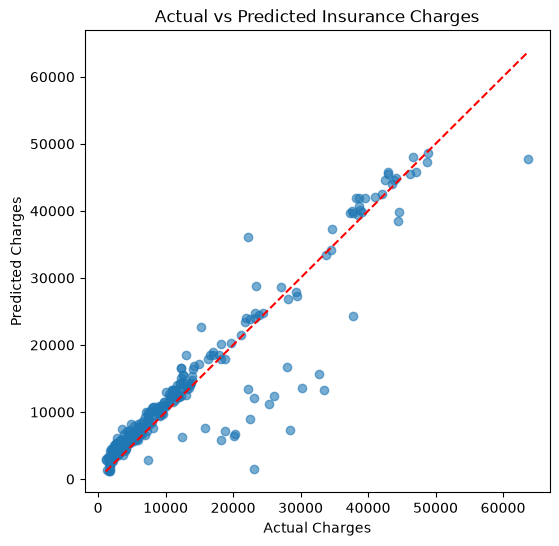

In [183]:
plt.figure(figsize=(6,6))
plt.scatter(Y_test, y_pred, alpha=0.6)

# Perfect prediction line
plt.plot([Y_test.min(), Y_test.max()],
         [Y_test.min(), Y_test.max()],
         color='red', linestyle='--')

plt.xlabel("Actual Charges")
plt.ylabel("Predicted Charges")
plt.title("Actual vs Predicted Insurance Charges")
plt.show()